In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.svm import SVR
df = pd.read_csv('~/ryan/DSML/DATASETS/Auto.csv')

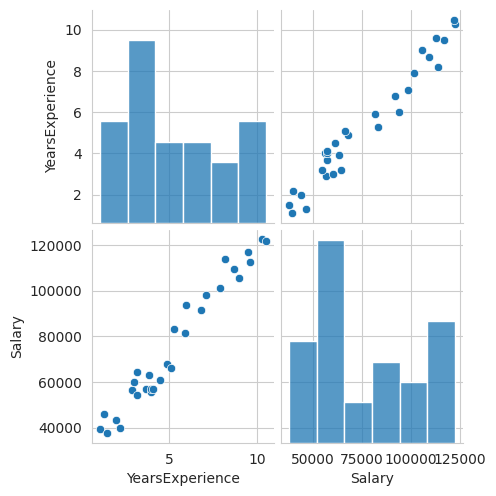

In [49]:
# sns.scatterplot(x='TV', y='sales', data=df);
sns.pairplot(df)

# NO SCALING

In [37]:
x = df[['TV']]
y = df[['sales']]

poly = PolynomialFeatures(degree=2)
x_poly = poly.fit_transform(x)

x_train, x_test, y_train, y_test = train_test_split(x_poly, y, test_size=0.2, random_state=0)
model = LinearRegression()
model.fit(x_train, y_train)

print('train score:', model.score(x_train, y_train))
print('test score:', model.score(x_test, y_test))

# mse = mean_squared_error(y_test.values, model.predict(x_test))
# print('MSE:', mse)
#
# x_val = pd.DataFrame({'TV': [50]})
# y_pred = model.predict(x_val)
# print('predicted value:', y_pred.squeeze())

train score: 0.6017654790678126
test score: 0.6604481473780814


In [38]:
scaler_x = StandardScaler()
scaler_y = StandardScaler()

x_scaled = scaler_x.fit_transform(x)
y_scaled = scaler_y.fit_transform(y)

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_scaled, test_size=0.2, random_state=0)


model = LinearRegression()
model.fit(x_train, y_train)

print('train score:', model.score(x_train, y_train))
print('test score:', model.score(x_test, y_test))

# type(y_test)


mse = mean_squared_error(y_test, model.predict(x_test))
print('MSE:', mse)

x_val = pd.DataFrame({'TV': [50]})
y_pred = model.predict(x_val)
y_pred = scaler_y.inverse_transform(y_pred)

print('predicted value:', y_pred.squeeze())

train score: 0.5884742462828709
test score: 0.6763151577939721
MSE: 0.37607170873903806
predicted value: 211.06141203673624


/home/ryan/miniconda3/envs/DSML/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


# OVERALL SCALLING

In [39]:
# x = df[['TV']]
# y = df[['sales']]
#
# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
#
# scaler_x = StandardScaler()
# scaler_y = StandardScaler()
#
# x_train_scaled = scaler_x.fit_transform(x_train)
# y_train_scaled = scaler_y.fit_transform(y_train)
#
# x_test_scaled = scaler_x.transform(x_test)
# y_test_scaled = scaler_y.transform(y_test)
#
# model = LinearRegression()
# model.fit(x_train_scaled, y_train_scaled)
#
# y_pred_scaled = model.predict(x_test_scaled)
# y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1,1))
# y_true = y_test.values  # original scale
#
# mse = mean_squared_error(y_true, y_pred)
#
# print('train score:', model.score(x_train_scaled, y_train_scaled))
# print('test score:', model.score(x_test_scaled, y_test_scaled))
#
# print('MSE:', mse)

In [40]:
# # Input TV value
# tv_value = 50
#
# # Wrap it in a DataFrame (matching training feature column)
# tv_df = pd.DataFrame({'TV': [tv_value]})
#
# # Scale the input TV value using the previously fitted scaler_x
# tv_scaled = scaler_x.transform(tv_df)
#
# # Predict scaled sales using the trained model
# sales_pred_scaled = model.predict(tv_scaled)
#
# # Inverse transform to get sales in original scale
# sales_pred = scaler_y.inverse_transform(sales_pred_scaled.reshape(-1, 1))
#
# print(f'Predicted sales for TV={tv_value}: {sales_pred[0, 0]}')

In [41]:
# x = df[['TV']]
# y = df[['sales']]
#
# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
#
# model = LinearRegression()
# model.fit(x_train, y_train)
#
# y_pred = model.predict(x_test)
# y_pred = scaler_y.inverse_transform(y_pred.reshape(-1,1))
# y_true = y_test.values  # original scale
#
# mse = mean_squared_error(y_true, y_pred)
#
# print('train score:', model.score(x_train, y_train))
# print('test score:', model.score(x_test, y_test))
#
# print('MSE:', mse)

In [42]:
# # sns.scatterplot(x='TV', y='sales', data=df);
#
# x_val = pd.DataFrame({'TV': [100]})  # keep feature name 'TV'
# y_pred = model.predict(x_val)     # predict returns array
# y_pred